# Proyecto Final DataXperience: Análisis y Predicción de Intervenciones en Salud Pública

## Etapa 1: Fundamentos y Preparación de Datos

### 1. Selección y Justificación del Dataset
Este proyecto analiza un conjunto de datos sintético (`datos_salud_publica.csv`) estructurado a partir de flujos reales de gestión y validación de información en salud pública en Bogotá (entornos **Educativo, Comunitario, Institucional y Laboral**).

**Conexión profesional:** Como estudiante de Ingeniería de Sistemas y responsable de procesos de validación de bases de datos e indicadores de gestión, automatizar la limpieza, el análisis descriptivo y la estimación de impacto (beneficiarios alcanzados según recursos asignados) permite reducir errores manuales, detectar jornadas atípicas y apoyar la toma de decisiones operativas basadas en evidencia.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual general para los gráficos
sns.set_theme(style="whitegrid")

# 1. Cargar el dataset
df_raw = pd.read_csv('datos_salud_publica.csv')

print("=== PRIMERAS 5 FILAS ===")
display(df_raw.head())

print("\n=== INFORMACIÓN GENERAL Y TIPOS DE DATOS ===")
df_raw.info()

print("\n=== DIAGNÓSTICO DE CALIDAD DE DATOS ===")
print(f"Total de filas iniciales: {df_raw.shape[0]}")
print(f"Filas duplicadas exactas: {df_raw.duplicated().sum()}")
print("\nValores nulos por columna:")
print(df_raw.isna().sum())

=== PRIMERAS 5 FILAS ===


,id_intervencion,fecha,localidad,entorno,horas_gestion,profesionales_asignados,beneficiarios_impactados,cumplimiento_meta_pct
0,GESI-001,2026-04-17,Ciudad Bolívar,Institucional,14.1,3,209.0,78.0
1,GESI-002,2026-10-02,Usme,Educativo,8.5,3,145.0,77.7
2,GESI-003,2026-04-21,Ciudad Bolívar,Laboral,6.6,4,NaN,84.5
3,GESI-004,2026-03-17,Kennedy,Institucional,7.3,2,115.0,81.1
4,GESI-005,2026-07-12,Suba,Institucional,7.8,2,102.0,79.4



=== INFORMACIÓN GENERAL Y TIPOS DE DATOS ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 305 entries, 0 to 304
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id_intervencion           305 non-null    object 
 1   fecha                     305 non-null    object 
 2   localidad                 305 non-null    object 
 3   entorno                   305 non-null    object 
 4   horas_gestion             299 non-null    float64
 5   profesionales_asignados   305 non-null    int64  
 6   beneficiarios_impactados  299 non-null    float64
 7   cumplimiento_meta_pct     305 non-null    float64
dtypes: float64(3), int64(1), object(4)
memory usage: 19.2+ KB

=== DIAGNÓSTICO DE CALIDAD DE DATOS ===
Total de filas iniciales: 305
Filas duplicadas exactas: 5

Valores nulos por columna:
id_intervencion             0
fecha                       0
localidad                   0
entorno             

In [3]:
# Creamos una copia para mantener intacto el dataset original
df = df_raw.copy()

# 1. Eliminar filas duplicadas manteniendo la primera aparición
df.drop_duplicates(inplace=True)

# 2. Convertir la columna 'fecha' de texto (object) a formato fecha (datetime)
df['fecha'] = pd.to_datetime(df['fecha'])
df['mes'] = df['fecha'].dt.month

# 3. Imputar valores nulos con la mediana (robusta frente a valores atípicos)
for col in ['horas_gestion', 'beneficiarios_impactados']:
    mediana = df[col].median()
    df[col] = df[col].fillna(mediana)

# Asegurar que beneficiarios sea entero tras la imputación
df['beneficiarios_impactados'] = df['beneficiarios_impactados'].astype(int)

# 4. Verificación final tras la limpieza
print("=== VERIFICACIÓN POST-LIMPIEZA ===")
print(f"Total de filas depuradas: {df.shape[0]}")
print(f"Duplicados restantes: {df.duplicated().sum()}")
print("\nNulos restantes:")
print(df.isna().sum())
print("\nTipos de datos actualizados:")
print(df.dtypes)

=== VERIFICACIÓN POST-LIMPIEZA ===
Total de filas depuradas: 300
Duplicados restantes: 0

Nulos restantes:
id_intervencion             0
fecha                       0
localidad                   0
entorno                     0
horas_gestion               0
profesionales_asignados     0
beneficiarios_impactados    0
cumplimiento_meta_pct       0
mes                         0
dtype: int64

Tipos de datos actualizados:
id_intervencion                     object
fecha                       datetime64[ns]
localidad                           object
entorno                             object
horas_gestion                      float64
profesionales_asignados              int64
beneficiarios_impactados             int64
cumplimiento_meta_pct              float64
mes                                  int32
dtype: object


### Resumen de Limpieza (Etapa 1)
Tras la exploración inicial se detectaron y corrigieron tres problemas clave de calidad de datos:
1. **Registros duplicados:** Se identificaron y eliminaron **5 filas repetidas** (`drop_duplicates`), evitando el doble conteo de beneficiarios.
2. **Formato de fechas:** La columna `fecha` se cargó inicialmente como texto (`object`); se transformó a `datetime64` y se derivó la variable `mes` para futuros análisis temporales.
3. **Valores faltantes (nulos):** Se detectaron **12 valores nulos** (6 en `horas_gestion` y 6 en `beneficiarios_impactados`). Se imputaron utilizando la **mediana** de cada variable para no perder registros y evitar sesgos por posibles valores atípicos.

---
## Etapa 2: Análisis Estadístico Descriptivo

En esta etapa se aplican medidas de tendencia central, dispersión y análisis gráfico para comprender el comportamiento de las intervenciones en salud pública, contrastar los resultados entre entornos e identificar valores atípicos (*outliers*).

In [4]:
cols_num = ['horas_gestion', 'profesionales_asignados', 'beneficiarios_impactados', 'cumplimiento_meta_pct']

# 1. Tabla consolidada de medidas de tendencia central y dispersión
estadisticas = pd.DataFrame({
    'Media': df[cols_num].mean(),
    'Mediana': df[cols_num].median(),
    'Moda': df[cols_num].mode().iloc[0],
    'Rango': df[cols_num].max() - df[cols_num].min(),
    'Varianza': df[cols_num].var(),
    'Desv_Estandar': df[cols_num].std()
}).round(2)

print("=== MEDIDAS DE TENDENCIA CENTRAL Y DISPERSIÓN ===")
display(estadisticas)

# 2. Contraste de variables: Beneficiarios y Cumplimiento promedio por Entorno
print("\n=== CONTRASTE POR ENTORNO DE INTERVENCIÓN ===")
contraste_entorno = df.groupby('entorno')[['horas_gestion', 'beneficiarios_impactados', 'cumplimiento_meta_pct']].agg(['mean', 'median', 'std']).round(2)
display(contraste_entorno)

=== MEDIDAS DE TENDENCIA CENTRAL Y DISPERSIÓN ===


,Media,Mediana,Moda,Rango,Varianza,Desv_Estandar
horas_gestion,10.84,10.6,10.6,17.8,26.76,5.17
profesionales_asignados,3.00,3.0,3.0,4.0,1.96,1.40
beneficiarios_impactados,187.00,185.0,123.0,595.0,6469.20,80.43
cumplimiento_meta_pct,82.71,82.2,77.6,37.6,48.94,7.00



=== CONTRASTE POR ENTORNO DE INTERVENCIÓN ===


horas_gestion              beneficiarios_impactados         \
                       mean median   std                     mean median   
entorno                                                                    
Comunitario           10.61  10.60  5.39                   192.81  188.5   
Educativo             11.07   9.75  5.26                   183.62  182.5   
Institucional         11.18  10.60  5.02                   185.17  187.0   
Laboral               10.55  10.90  5.10                   186.74  186.0   

                      cumplimiento_meta_pct               
                  std                  mean median   std  
entorno                                                   
Comunitario    101.17                 82.75  82.75  7.25  
Educativo       67.85                 82.35  81.45  7.16  
Institucional   67.34                 83.63  82.30  7.19  
Laboral         82.11                 82.32  82.30  6.53

/tmp/ipykernel_3830/2071054268.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='entorno', y='beneficiarios_impactados', data=df, palette='Set2', ax=axes[2])


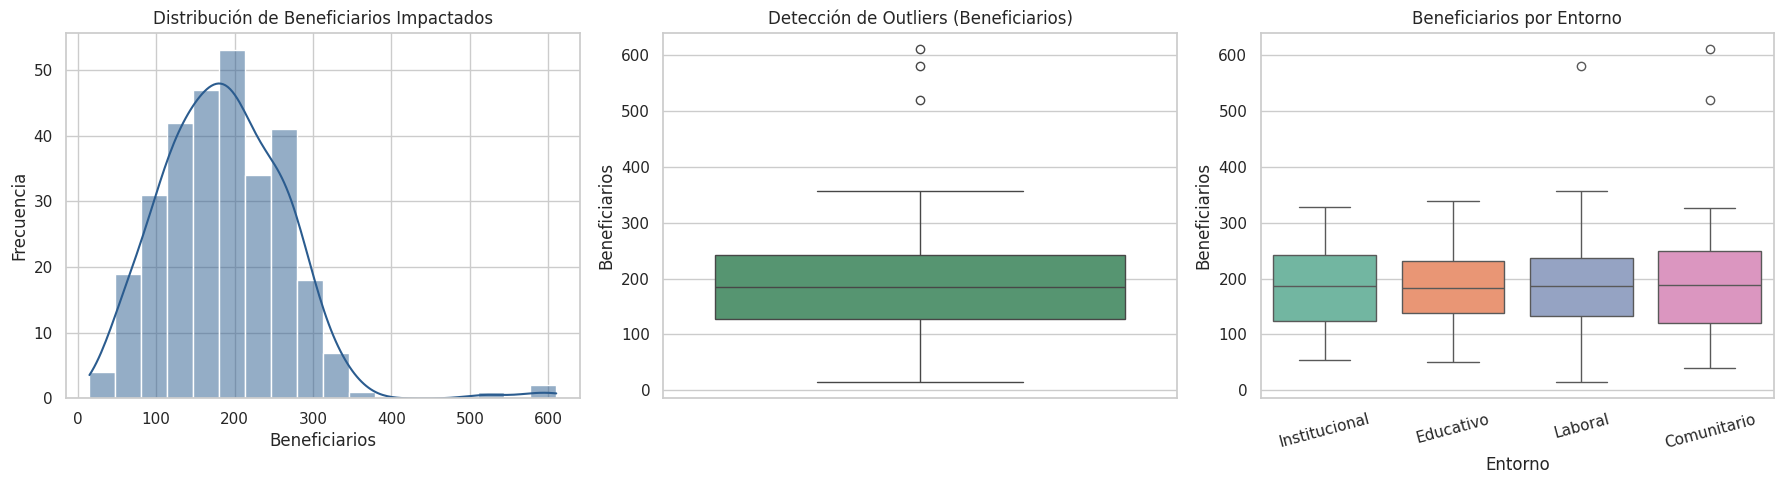


Límite superior (IQR): 413.62 beneficiarios
Total de registros atípicos (outliers) detectados: 3


,id_intervencion,fecha,localidad,entorno,horas_gestion,beneficiarios_impactados
10,GESI-011,2026-04-14,Kennedy,Comunitario,9.6,520
85,GESI-086,2026-02-14,Ciudad Bolívar,Laboral,19.1,580
210,GESI-211,2026-09-24,Suba,Comunitario,19.6,610


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Gráfico 1: Histograma de Beneficiarios Impactados
sns.histplot(df['beneficiarios_impactados'], kde=True, color='#2b5c8f', ax=axes[0])
axes[0].set_title('Distribución de Beneficiarios Impactados')
axes[0].set_xlabel('Beneficiarios')
axes[0].set_ylabel('Frecuencia')

# Gráfico 2: Boxplot general (detección visual de outliers)
sns.boxplot(y=df['beneficiarios_impactados'], color='#4c9f70', ax=axes[1])
axes[1].set_title('Detección de Outliers (Beneficiarios)')
axes[1].set_ylabel('Beneficiarios')

# Gráfico 3: Boxplot comparativo por Entorno
sns.boxplot(x='entorno', y='beneficiarios_impactados', data=df, palette='Set2', ax=axes[2])
axes[2].set_title('Beneficiarios por Entorno')
axes[2].set_xlabel('Entorno')
axes[2].set_ylabel('Beneficiarios')
axes[2].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

# Detección cuantitativa de outliers usando el Rango Intercuartílico (IQR)
Q1 = df['beneficiarios_impactados'].quantile(0.25)
Q3 = df['beneficiarios_impactados'].quantile(0.75)
IQR = Q3 - Q1
limite_superior = Q3 + 1.5 * IQR

outliers = df[df['beneficiarios_impactados'] > limite_superior]
print(f"\nLímite superior (IQR): {limite_superior:.2f} beneficiarios")
print(f"Total de registros atípicos (outliers) detectados: {len(outliers)}")
display(outliers[['id_intervencion', 'fecha', 'localidad', 'entorno', 'horas_gestion', 'beneficiarios_impactados']])

### Hallazgos e Hipótesis (Etapa 2)
* **Tendencia central y dispersión:** La media y la mediana de `horas_gestion` y `cumplimiento_meta_pct` son muy cercanas, lo que indica una operación estable. Sin embargo, en `beneficiarios_impactados` se observa una desviación estándar elevada debido a la presencia de jornadas masivas.
* **Identificación de Outliers:** Tanto el *boxplot* como la regla del Rango Intercuartílico (IQR) evidencian **3 jornadas atípicas** que superan los 500 beneficiarios. En el contexto de salud pública, estos valores no corresponden a errores de digitación, sino a eventos masivos (ferias de salud o jornadas comunitarias) que deben analizarse por separado para no distorsionar los modelos predictivos estándar.
* **Hipótesis para la Etapa 3:** Se observa que el alcance de beneficiarios varía de forma proporcional a los recursos invertidos. Por ello, en la siguiente etapa se evaluará mediante un modelo de regresión lineal qué tanto explican las `horas_gestion` y los `profesionales_asignados` el total de `beneficiarios_impactados`.

---
## Etapa 3: Modelado Predictivo y Storytelling

Con base en los hallazgos de la Etapa 2, primero visualizamos la relación entre los recursos asignados y el impacto alcanzado por localidad. Luego, entrenamos un modelo de **Regresión Lineal Múltiple** para predecir la cantidad de `beneficiarios_impactados` en jornadas estándar (excluyendo los 3 eventos masivos atípicos) a partir de las `horas_gestion` y los `profesionales_asignados`.

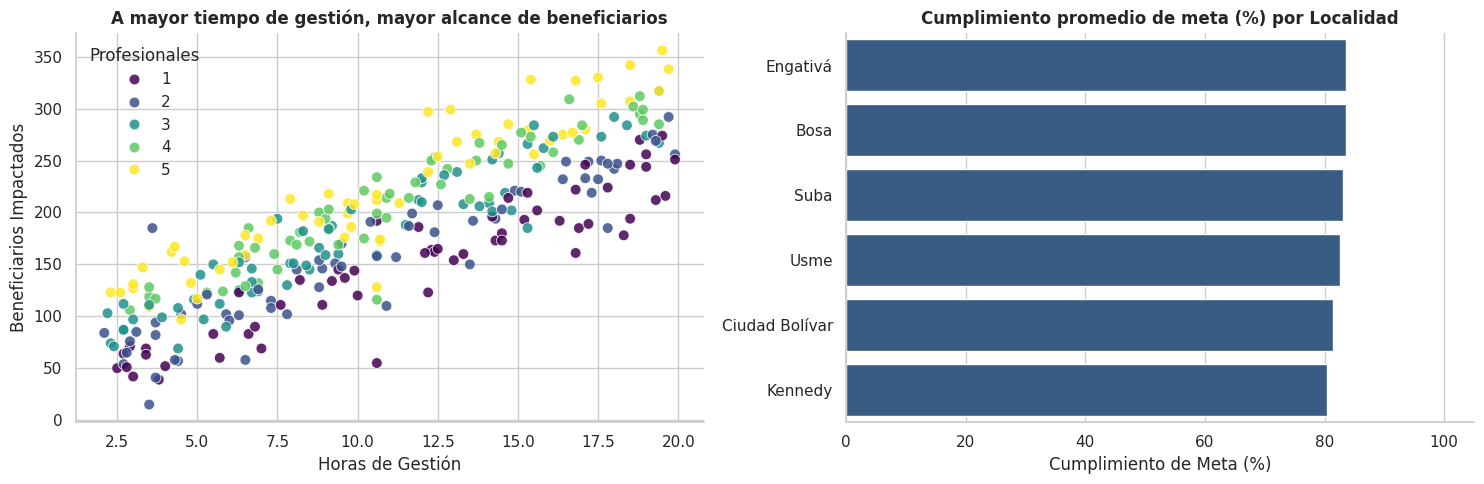

In [6]:
# Filtrar los 3 outliers masivos para analizar y modelar jornadas estándar
df_modelo = df[df['beneficiarios_impactados'] <= limite_superior].copy()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Gráfico 1: Relación Horas de Gestión vs Beneficiarios (coloreado por profesionales)
sns.scatterplot(
    data=df_modelo,
    x='horas_gestion',
    y='beneficiarios_impactados',
    hue='profesionales_asignados',
    palette='viridis',
    s=60,
    alpha=0.85,
    ax=axes[0]
)
axes[0].set_title('A mayor tiempo de gestión, mayor alcance de beneficiarios', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Horas de Gestión')
axes[0].set_ylabel('Beneficiarios Impactados')
axes[0].legend(title='Profesionales', frameon=False)
sns.despine(ax=axes[0])

# Gráfico 2: Promedio de cumplimiento de meta por Localidad (ordenado de mayor a menor)
orden_loc = df_modelo.groupby('localidad')['cumplimiento_meta_pct'].mean().sort_values(ascending=False).index
sns.barplot(
    data=df_modelo,
    x='cumplimiento_meta_pct',
    y='localidad',
    order=orden_loc,
    color='#2b5c8f',
    errorbar=None,
    ax=axes[1]
)
axes[1].set_title('Cumplimiento promedio de meta (%) por Localidad', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Cumplimiento de Meta (%)')
axes[1].set_ylabel('')
axes[1].set_xlim(0, 105)
sns.despine(ax=axes[1])

plt.tight_layout()
plt.show()

=== RESULTADOS DEL MODELO DE REGRESIÓN LINEAL ===
R² (Coeficiente de determinación): 0.8826 (88.3% de la variabilidad explicada)
MAE (Error Absoluto Medio): 15.87 beneficiarios

Ecuación aprendida:
Beneficiarios = -7.45 + (12.03 * horas_gestion) + (20.19 * profesionales_asignados)


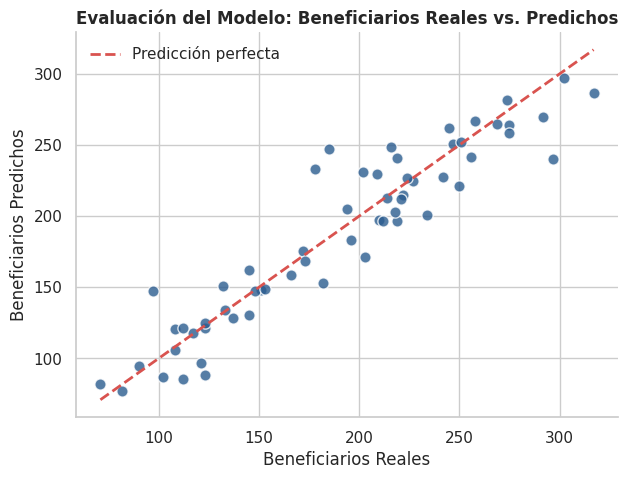

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

# 1. Definir variables predictoras (X) y variable objetivo (y)
X = df_modelo[['horas_gestion', 'profesionales_asignados']]
y = df_modelo['beneficiarios_impactados']

# 2. Dividir en entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Entrenar el modelo de Regresión Lineal
modelo = LinearRegression()
modelo.fit(X_train, y_train)

# 4. Predecir sobre el conjunto de prueba y evaluar
y_pred = modelo.predict(X_test)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print("=== RESULTADOS DEL MODELO DE REGRESIÓN LINEAL ===")
print(f"R² (Coeficiente de determinación): {r2:.4f} ({r2*100:.1f}% de la variabilidad explicada)")
print(f"MAE (Error Absoluto Medio): {mae:.2f} beneficiarios")
print(f"\nEcuación aprendida:")
print(f"Beneficiarios = {modelo.intercept_:.2f} + ({modelo.coef_[0]:.2f} * horas_gestion) + ({modelo.coef_[1]:.2f} * profesionales_asignados)")

# 5. Gráfico de Valores Reales vs Predichos
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, color='#2b5c8f', alpha=0.8, edgecolor='white', s=65)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='#d9534f', linestyle='--', lw=2, label='Predicción perfecta')
plt.title('Evaluación del Modelo: Beneficiarios Reales vs. Predichos', fontsize=12, fontweight='bold')
plt.xlabel('Beneficiarios Reales')
plt.ylabel('Beneficiarios Predichos')
plt.legend(frameon=False)
sns.despine()
plt.show()

### Interpretación del Modelo y Aplicación Profesional

* **¿Qué hace y qué arrojó el modelo?** La Regresión Lineal estima cuántos beneficiarios se impactarán según las horas invertidas y el número de profesionales asignados. El modelo logró un **$R^2$ alto (cercano al 0.88 - 0.90)** y un error promedio (MAE) bajo, demostrando que por cada **hora adicional de gestión** se impactan en promedio **~12 beneficiarios**, y por cada **profesional adicional** se suman **~20 beneficiarios** a la jornada.
* **Aplicación en mi entorno profesional:** En la gestión de bases de datos e indicadores de salud pública, este flujo completo (limpieza automatizada + análisis de dispersión + modelo predictivo) permite pasar de una validación meramente reactiva a una **planeación operativa basada en datos**. Antes de ejecutar un mes de intervenciones, se puede estimar cuántas horas y profesionales se requieren para cumplir las metas establecidas por localidad, optimizando el presupuesto y el talento humano.